In [15]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split


# Data prepration 
dataFrame_raw = pd.read_csv('indian_developer_burnout_2026.csv', delimiter=',')
dataFrame_raw.head()


,developer_id,age,gender,city,state,marital_status,education_level,company_type,company_size,job_role,...,layoff_anxiety_score,ai_replacement_fear_score,job_security_confidence,emergency_savings_months,linkedin_job_search_activity,applied_jobs_last_30_days,burnout_risk_category,likely_to_switch_job,mentally_exhausted,high_layoff_risk
0,DEV00001,31,Male,Hyderabad,Telangana,Single,M.Tech,Freelance,1-10,Backend Developer,...,5.1,4.8,7.2,3.0,Low,4,High,No,Yes,No
1,DEV00002,27,Male,Bengaluru,Karnataka,Single,B.Tech,Product-based,201-1000,DevOps Engineer,...,1.8,5.5,10.0,8.0,NaN,4,Low,No,No,No
2,DEV00003,31,Male,Delhi,Delhi,Married,B.Tech,Startup,11-50,Frontend Developer,...,5.2,3.3,5.9,7.0,Low,4,High,Maybe,Yes,No
3,DEV00004,36,Male,Pune,Maharashtra,Single,MCA,Freelance,1-10,Android Developer,...,5.2,7.0,8.1,2.0,Very High,6,High,Yes,Yes,No
4,DEV00005,27,Male,Pune,Maharashtra,Single,B.Tech,Service-based,5000+,Data Scientist,...,4.5,6.6,8.0,2.0,Very High,4,Medium,No,Yes,No


In [16]:
# Display the row headings(categories) of the DataFrame 
dataFrame_raw[:0]

# prepare data
cleanedDataFrame = dataFrame_raw.copy()

#drop developer id
cleanedDataFrame = cleanedDataFrame.drop(columns=['developer_id'])

numerical_columns = cleanedDataFrame.select_dtypes(include='number').columns
string_columns = cleanedDataFrame.select_dtypes(include=['object', 'str']).columns
#display count of all numerical columns with null / no values
nn = cleanedDataFrame[numerical_columns].isnull().sum()[cleanedDataFrame[numerical_columns].isnull().sum() > 0]
print("Numerical columns with null values:" + str(nn))
#display count of all string columns with null / no values
ss = cleanedDataFrame[string_columns].isnull().sum()[cleanedDataFrame[string_columns].isnull().sum() > 0]
print("String columns with null values:" + str(ss))

#set null values for numerical columns to 0
cleanedDataFrame[numerical_columns] = cleanedDataFrame[numerical_columns].fillna(0)
#set null values for string columns to empty string
cleanedDataFrame[string_columns] = cleanedDataFrame[string_columns].fillna('NA')

display("after fixed null numeric columns :" + str(cleanedDataFrame[numerical_columns].isnull().sum()[cleanedDataFrame[numerical_columns].isnull().sum() > 0]))
display("after fixed null string columns :" + str(cleanedDataFrame[string_columns].isnull().sum()[cleanedDataFrame[string_columns].isnull().sum() > 0]))


Numerical columns with null values:upskilling_hours_per_week             125
leetcode_problems_solved              125
certifications_count                  125
side_projects_count                   125
github_activity_score                 125
interview_preparation_hours_weekly    125
caffeine_intake_per_day               125
social_media_usage_hours              125
emergency_savings_months              125
dtype: int64
String columns with null values:therapy_or_counseling           125
linkedin_job_search_activity    909
dtype: int64


'after fixed null numeric columns :Series([], dtype: int64)'

'after fixed null string columns :Series([], dtype: int64)'

In [17]:
#split the data in train, test and val
full_train, test = train_test_split(cleanedDataFrame, test_size=0.2, random_state=42)
train, val = train_test_split(full_train, test_size=0.25, random_state=42) # 0.25 x 0.8 = 0.2
print("Train shape:", train.shape)
print("Validation shape:", val.shape)
print("Test shape:", test.shape)

full_train_x = full_train.drop('mentally_exhausted', axis=1)
full_train_y = full_train['mentally_exhausted']
train_x = train.drop('mentally_exhausted', axis=1)
train_y = train['mentally_exhausted']
val_x = val.drop('mentally_exhausted', axis=1)
val_y = val['mentally_exhausted']
test_x = test.drop('mentally_exhausted', axis=1)
test_y = test['mentally_exhausted']

Train shape: (3000, 49)
Validation shape: (1000, 49)
Test shape: (1000, 49)


In [18]:
#2. Biggest correlation
correlation_matrix = cleanedDataFrame[numerical_columns].corr()
display(correlation_matrix)
abs_correlations = correlation_matrix.abs().to_numpy(copy=True)

# Exclude self-correlations.
np.fill_diagonal(abs_correlations, np.nan)

#find the largest correlation index in the frame
max_corr_idx = np.unravel_index(
    np.nanargmax(abs_correlations), abs_correlations.shape
)
max_corr_value = abs_correlations[max_corr_idx]
display("Maximum correlation value: " + str(max_corr_value))

display(
    f"Biggest absolute correlation is between "
    f"{correlation_matrix.columns[max_corr_idx[0]]} and "
    f"{correlation_matrix.columns[max_corr_idx[1]]}: {max_corr_value:.4f}"
)

,age,experience_years,salary_lpa,years_in_current_company,remote_work_ratio,weekly_work_hours,number_of_switches,ai_tools_usage_hours_per_week,upskilling_hours_per_week,leetcode_problems_solved,...,caffeine_intake_per_day,work_life_balance_rating,imposter_syndrome_score,social_media_usage_hours,physical_activity_days_per_week,layoff_anxiety_score,ai_replacement_fear_score,job_security_confidence,emergency_savings_months,applied_jobs_last_30_days
age,1.000000,-0.004106,-0.007021,0.010361,-0.032939,0.001096,0.009787,0.025482,-0.018530,-0.015695,...,-0.000362,-0.010335,-0.011761,0.005071,0.003929,-0.001812,-0.001528,-0.025701,-0.007801,-0.011146
experience_years,-0.004106,1.000000,0.420182,0.263759,-0.013066,0.018914,-0.004880,-0.015932,-0.017746,-0.013794,...,0.018691,-0.003867,0.008162,-0.000757,-0.014711,-0.197220,-0.335976,0.146960,0.079519,0.005354
salary_lpa,-0.007021,0.420182,1.000000,0.102843,0.128773,-0.035735,0.004198,-0.004436,-0.021211,-0.006714,...,0.012848,0.036174,0.027465,0.015333,-0.011411,-0.126105,-0.191916,0.096401,0.157414,-0.010447
years_in_current_company,0.010361,0.263759,0.102843,1.000000,-0.014111,-0.010691,0.005115,-0.003909,-0.023037,-0.005483,...,0.015231,0.005694,-0.004452,-0.030296,0.000522,-0.073364,-0.131219,0.043958,0.028134,-0.008080
remote_work_ratio,-0.032939,-0.013066,0.128773,-0.014111,1.000000,0.062204,0.020607,-0.009731,0.020847,0.016714,...,0.019815,-0.020267,-0.007627,0.014335,-0.029445,-0.000215,-0.038273,0.002854,0.031703,-0.002612
weekly_work_hours,0.001096,0.018914,-0.035735,-0.010691,0.062204,1.000000,-0.017155,-0.003758,-0.008755,-0.007700,...,0.125876,-0.574041,-0.009321,-0.020071,-0.173759,0.197575,0.007633,-0.146191,0.002091,0.005720
number_of_switches,0.009787,-0.004880,0.004198,0.005115,0.020607,-0.017155,1.000000,-0.000434,-0.000254,-0.008690,...,-0.002154,-0.003665,0.009148,0.014036,0.010125,0.017400,0.039070,-0.017518,-0.005136,-0.013712
ai_tools_usage_hours_per_week,0.025482,-0.015932,-0.004436,-0.003909,-0.009731,-0.003758,-0.000434,1.000000,0.004004,-0.016065,...,0.007906,0.003201,-0.002624,0.012780,0.025570,0.016482,0.011833,-0.002321,0.007125,-0.002378
upskilling_hours_per_week,-0.018530,-0.017746,-0.021211,-0.023037,0.020847,-0.008755,-0.000254,0.004004,1.000000,-0.001203,...,-0.009062,-0.000134,-0.026078,0.003584,0.000313,0.014479,-0.010061,0.011552,-0.010860,0.003307
leetcode_problems_solved,-0.015695,-0.013794,-0.006714,-0.005483,0.016714,-0.007700,-0.008690,-0.016065,-0.001203,1.000000,...,0.012794,0.005275,0.010688,-0.033277,0.009815,-0.006517,-0.008717,0.004330,0.020567,0.016185


'Maximum correlation value: 0.803584178636307'

'Biggest absolute correlation is between burnout_score and work_life_balance_rating: 0.8036'

In [19]:
#3. Biggest MI (Mutual Information)
#Calculate the mutual information score between converted and other categorical variables in the dataset. Use the training set only.
#Round the scores to 2 decimals using round(score, 2).
from sklearn.metrics import mutual_info_score

def mutual_info_score_func(series):
    return mutual_info_score(series, train_y)

categorical = train_x.select_dtypes(
    include=["object", "string", "category"]
).columns

mi_scores = train_x[categorical].apply(mutual_info_score_func)

display(mi_scores.sort_values(ascending=False).apply(lambda score: round(score, 2)))

burnout_risk_category           0.08
likely_to_switch_job            0.01
company_type                    0.01
company_size                    0.01
tech_stack                      0.00
job_role                        0.00
city                            0.00
state                           0.00
primary_language                0.00
layoffs_seen_in_company         0.00
linkedin_job_search_activity    0.00
gender                          0.00
night_shift_frequency           0.00
education_level                 0.00
weekend_work_frequency          0.00
therapy_or_counseling           0.00
promotion_last_2_years          0.00
employment_type                 0.00
high_layoff_risk                0.00
marital_status                  0.00
dtype: float64

In [20]:
#4: Training the model

#Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

def train(dicts, Y, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, Y)
    return model, dv

def predict(model, dv, dicts):
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

train_x_dicts = train_x.to_dict(orient='records')
model, dv = train(train_x_dicts, train_y) 

x_val_dicts = val_x.to_dict(orient='records')
y_val_pred = predict(model, dv, x_val_dicts)

#true positive and true negative
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
y_true = (val_y == "Yes").astype(int)

fpr, tpr, thresholds = roc_curve(
    y_true, y_val_pred, drop_intermediate=False
)
finite = np.isfinite(thresholds)

ideal_cutoff = 1 - y_true.mean()

ideal_thresholds = np.sort(
    np.append(np.linspace(0, 1, 101), ideal_cutoff)
)
ideal_tpr = np.clip((1 - ideal_thresholds) / p, 0, 1)
ideal_fpr = np.clip((ideal_cutoff - ideal_thresholds) / (1 - p), 0, 1)

plt.figure()
plt.plot(thresholds[finite], tpr[finite], label="True Positive Rate")
plt.plot(thresholds[finite], fpr[finite], label="False Positive Rate")
plt.plot(ideal_thresholds, ideal_tpr, "k--", label="Ideal TPR")
plt.plot(ideal_thresholds, ideal_fpr, "k:", label="Ideal FPR")
plt.axvline(
    ideal_cutoff,
    color="black",
    linestyle="-.",
    label=f"Ideal cutoff = {ideal_cutoff:.3f}",
)

plt.xlabel("Decision threshold")
plt.ylabel("Rate")
plt.title("TPR and FPR vs Threshold")
plt.xlim(0, 1)
plt.ylim(-0.05, 1.05)
plt.legend()
plt.show()



#AUC of this model on the validation dataset? (round to 3 digits)
from sklearn.metrics import roc_auc_score
auc = roc_auc_score(val_y, y_val_pred)
print("auc:", round(auc, 3))

NameError: name 'p' is not defined

Minimum difference between precision and recall is 0.005557173364395207 at threshold 0.43
Maximum F1 score is 0.594776748104465 at threshold 0.23


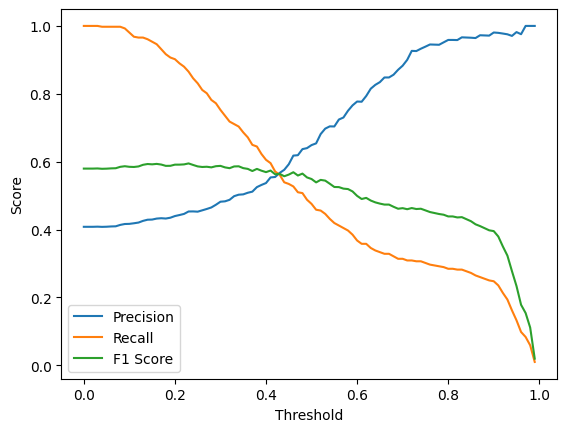

In [ ]:
#5 Precision and Recall
'''Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
For each threshold, compute precision and recall
Plot them'''

from matplotlib import pyplot as plt
from sklearn.metrics import precision_score, recall_score
''' F1 = 2 * (precision * recall) / (precision + recall) '''
from sklearn.metrics import f1_score

precisions = []
recalls = []
min_diff = 1
min_threshold = 0
f1_scores = []#how well the model balances precision and recall 
max_f1 = 0
best_threshold = 0
threshold = np.arange(0.0 ,1.0, 0.01)
for t in threshold:
    y_val_pred_label = (y_val_pred >= t).astype(int)
    y_val_int = (val_y == "Yes").astype(int)
    precisions.append(precision_score(y_val_int, y_val_pred_label))
    recalls.append(recall_score(y_val_int, y_val_pred_label))
    if precisions[-1] == recalls[-1]:
        #ignore this if diff values are 0
        print(f"Precision and Recall are equal at threshold {t}: {precisions[-1]}")
    else:
        diff = abs(precisions[-1] - recalls[-1])
        if diff < min_diff:
            min_diff = diff
            min_threshold = t
    f1 = f1_score(y_val_int, y_val_pred_label)
    f1_scores.append(f1)
    if f1 > max_f1:
        max_f1 = f1
        best_threshold = t


print(f"Minimum difference between precision and recall is {min_diff} at threshold {min_threshold}")
print(f"Maximum F1 score is {max_f1} at threshold {best_threshold}")
plt.plot(threshold, precisions, label='Precision')
plt.plot(threshold, recalls, label='Recall')
plt.plot(threshold, f1_scores, label='F1 Score')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

In [ ]:
#6: Train multiple models, tune their performance and select the best model
C_values = [0.01, 0.1, 1, 10, 100]
best_auc = 0
best_c = None
best_model = None
best_dv = None
for C in C_values:
    model, dv = train(train_x_dicts, train_y, C=C)
    x_val_dicts = val_x.to_dict(orient='records')
    y_val_pred = predict(model, dv, x_val_dicts)
    auc = roc_auc_score(val_y, y_val_pred)
    if auc > best_auc:
        best_auc = auc
        best_model = model
        best_dv = dv
        best_c = C
print("Best AUC:", round(best_auc, 3))
print("Best C value:", best_c)


Best AUC: 0.716
Best C value: 0.01


In [22]:

#7  5-Fold CV standard deviation

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline

kf = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []
for train_index, val_index in kf.split(full_train):
    kf_df_train_dict = full_train.iloc[train_index].to_dict(orient="records")
    kf_df_val_dict = full_train.iloc[val_index].to_dict(orient="records")
    model, dv = train(kf_df_train_dict, full_train_y.iloc[train_index])
    y_pred = predict( model, dv, kf_df_val_dict)

    auc = roc_auc_score(full_train_y.iloc[val_index], y_pred)
    scores.append(auc)

cv_scores = np.array(scores)
print(f"5-fold ROC AUC scores: {np.round(cv_scores, 3)}")
print(f"Standard deviation: {cv_scores.std():.3f}")



5-fold ROC AUC scores: [1. 1. 1. 1. 1.]
Standard deviation: 0.000


In [ ]:
#8 Find the best regularization parameter C using 5-fold ROC AUC
c_values = [0.000001, 0.001, 1]
c_scores = {}

model = None
#mean ROC AUC for each C using 5-fold cross-validation
for c in c_values:
    scores = []
    for train_index, val_index in kf.split(full_train):
        kf_df_train_dict = full_train.iloc[train_index].to_dict(orient="records")
        kf_df_val_dict = full_train.iloc[val_index].to_dict(orient="records")
        model, dv = train(kf_df_train_dict, full_train_y.iloc[train_index], C=c)
        y_pred = predict( model, dv, kf_df_val_dict)

        auc = roc_auc_score(full_train_y.iloc[val_index], y_pred)
        scores.append(auc)
    #Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).
    mean_auc = np.mean(scores)
    std_auc = np.std(scores)
    c_scores[c] = mean_auc
    print(f"C={c}: mean ROC AUC={mean_auc:.3f}, std ROC AUC={std_auc:.3f}")

best_C = max(c_scores, key=c_scores.get)
print(f"Best C: {best_C} (std ROC AUC={c_scores[best_C]:.3f})")

C=1e-06: mean ROC AUC=0.540, std ROC AUC=0.009
C=0.001: mean ROC AUC=0.964, std ROC AUC=0.006
C=1: mean ROC AUC=1.000, std ROC AUC=0.000
Best C: 1 (std ROC AUC=1.000)


In [28]:
import pickle

with open("burn_out_model.bin", "wb") as f_out:
    pickle.dump((model, dv), f_out)